# Tarea 3 — Segmentación de clientes (K-Means)

easyMoney · TFM Nuclio Digital School

**Objetivo.** Responder a la petición de Carol: segmentar la base en **7 u 8 grupos** de clientes similares. Agrupamos a los clientes combinando su situación en un mes de referencia (productos, edad, renta, segmento) con su comportamiento acumulado (antigüedad, compras, margen) y traducimos los grupos en perfiles y oportunidades comerciales.

**Datos.** La base común `df_panel_limpio.parquet` (ver `01_base_comun`), ya limpia, sin fallecidos y con las ventas agregadas por cliente-mes. Aquí no se repite ninguna limpieza.

### Por qué el modelo se ajusta con abril y no con mayo

La Tarea 4 mide cuántos clientes de cada grupo contratan un producto nuevo en **mayo 2019**. Si los grupos se construyeran con la foto de mayo, habría leakage: un cliente que contrata el plan de pensiones en mayo ya aparecería con el plan en esa foto, caería en un grupo donde el plan de pensiones es habitual (como "Particulares con nómina") y haría que ese grupo pareciera convertir más de lo real.

Por eso trabajamos en dos pasos:
1. **El K-Means se ajusta con la foto de abril 2019** y el histórico hasta abril → `clientes_grupos_abril.csv`. Con estos grupos, la Tarea 4 evalúa las conversiones de mayo sin usar información del futuro.
2. **Los grupos para la campaña** se asignan con la foto de mayo, aplicando `kmeans.predict()` con el modelo y el escalado de abril, sin reentrenar → `clientes_grupos.csv`.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

RUTA = '../data/processed/'
df = pd.read_parquet(RUTA + 'df_panel_limpio.parquet', engine='pyarrow')

PRODUCT_COLS = ['short_term_deposit', 'loans', 'mortgage', 'funds', 'securities',
                'long_term_deposit', 'em_account_pp', 'credit_card', 'payroll',
                'pension_plan', 'payroll_account', 'emc_account', 'debit_card',
                'em_account_p', 'em_acount']

meses = sorted(df['pk_partition'].unique())
MES_AJUSTE, MES_ULTIMO = pd.Timestamp(meses[-2]), pd.Timestamp(meses[-1])
print('Panel:', df.shape)
print('Mes de ajuste del K-Means:', MES_AJUSTE.strftime('%Y-%m'), '| último mes:', MES_ULTIMO.strftime('%Y-%m'))

Panel: (5961849, 29)
Mes de ajuste del K-Means: 2019-04 | último mes: 2019-05


## 1. Tabla de clientes en un mes de referencia

Una fila por cliente con:
- **Foto del mes:** productos, edad, salary, segmento, actividad.
- **Histórico hasta ese mes (incluido):** compras y margen acumulados, meses con compra y meses activo.
- **`antiguedad_meses`:** meses desde `entry_date`.

Se encapsula en una función para construir exactamente la misma tabla con abril y con mayo.

In [4]:
def construir_tabla_clientes(df, ref_mes):
    hist = df[df['pk_partition'] <= ref_mes]
    foto = hist[hist['pk_partition'] == ref_mes].copy()

    foto['n_productos'] = foto[PRODUCT_COLS].sum(axis=1)
    foto['antiguedad_meses'] = ((ref_mes.year - foto['entry_date'].dt.year) * 12
                                + (ref_mes.month - foto['entry_date'].dt.month)).clip(lower=0)

    acumulado = (hist.assign(con_compra=(hist['n_compras_mes'] > 0).astype(int))
                 .groupby('pk_cid')
                 .agg(n_compras=('n_compras_mes', 'sum'),
                      margen_total=('margen_mes', 'sum'),
                      meses_con_compra=('con_compra', 'sum'),
                      meses_activo=('active_customer', 'sum'))
                 .reset_index())
    return foto.merge(acumulado, on='pk_cid', how='left')

clientes = construir_tabla_clientes(df, MES_AJUSTE)
print('Clientes en la foto de', MES_AJUSTE.strftime('%Y-%m'), ':', len(clientes),
      '| únicos:', clientes['pk_cid'].nunique())
print('Con alguna compra hasta ese mes:', (clientes['n_compras'] > 0).sum(),
      f"({(clientes['n_compras'] > 0).mean():.1%})")

Clientes en la foto de 2019-04 : 439543 | únicos: 439543
Con alguna compra hasta ese mes: 146092 (33.2%)


## 2. Clientes sin ningún producto

Una cuarta parte de la base (25 %) no tiene ningún producto contratado, y solo un 4 % de ellos figura como activo. Se tratan como grupo de negocio propio (**grupo 0, "Sin producto"**) y no entran en el K-Means, porque arrastrarían los centroides hacia "no tener nada". Al final de la sección 7 se comprueba que el propio K-Means también los separa.

In [5]:
print(clientes['n_productos'].value_counts().sort_index())

sin_prod = clientes[clientes['n_productos'] == 0]
print(f'\nSin producto: {len(sin_prod)} ({len(sin_prod) / len(clientes):.1%})')
print('Activos entre ellos:', f"{sin_prod['active_customer'].mean():.1%}")
print(sin_prod['segment'].value_counts().head())

n_productos
0    109992
1    268012
2     38216
3     10991
4      7977
5      3144
6       987
7       192
8        31
9         1
Name: count, dtype: int64

Sin producto: 109992 (25.0%)
Activos entre ellos: 4.4%
segment
03 - UNIVERSITARIO    60822
02 - PARTICULARES     48174
01 - TOP                582
Desconocido             414
Name: count, dtype: int64


In [6]:
df_sin_producto = clientes[clientes['n_productos'] == 0].copy()
df_con_producto = clientes[clientes['n_productos'] >= 1].copy().reset_index(drop=True)
print('Sin producto:', len(df_sin_producto), '| Con producto:', len(df_con_producto),
      '| Total:', len(df_sin_producto) + len(df_con_producto))

Sin producto: 109992 | Con producto: 329551 | Total: 439543


## 3. `salary`: ya viene imputado

`salary` llega imputado desde `01_base_comun` (historia del cliente → mediana de clientes parecidos), así que aquí no se imputa. Solo comprobamos que no hay nulos y cuántos clientes de la foto tienen el salario estimado.

In [7]:
assert df_con_producto['salary'].notnull().all(), 'Hay salary nulo: ejecuta antes el 01_base_comun'
print(f"Clientes con salary estimado en la foto: {df_con_producto['salary_imputado'].sum()} "
      f"({df_con_producto['salary_imputado'].mean():.1%})")

Clientes con salary estimado en la foto: 101666 (30.8%)


## 4. Selección de variables

- **Productos:** solo los que tienen varianza útil. Un producto con presencia casi del 0 % o del 100 % no aporta nada a la distancia. Se descartan `loans`, `mortgage`, `short_term_deposit`, `em_account_p` y `em_account_pp` (presencia ≤ 0,01 %).
- **Numéricas:** comprobamos que no haya pares muy correlacionados (> 0,7-0,8), porque pesarían el doble en la distancia euclídea. El único par cerca del umbral es `n_compras`–`margen_total` (0,74); se mantienen las dos porque una mide la frecuencia de compra y la otra el valor económico del cliente.

In [8]:
presencia = (df_con_producto[PRODUCT_COLS].mean() * 100).sort_values(ascending=False)
print(presencia.round(2))

em_acount             89.76
debit_card            12.78
payroll_account        7.74
emc_account            7.11
pension_plan           4.92
payroll                4.62
long_term_deposit      1.93
credit_card            1.44
securities             0.54
funds                  0.40
loans                  0.01
mortgage               0.01
short_term_deposit     0.00
em_account_p           0.00
em_account_pp          0.00
dtype: float64


In [9]:
VARS_NUM  = ['age', 'salary', 'n_productos', 'antiguedad_meses', 'n_compras', 'margen_total']
VARS_PROD = ['em_acount', 'debit_card', 'payroll_account', 'emc_account', 'pension_plan',
             'payroll', 'long_term_deposit', 'credit_card', 'securities', 'funds']
VARS_LOG  = ['salary', 'n_productos', 'n_compras', 'margen_total']
SEGMENTOS = ['01 - TOP', '02 - PARTICULARES', '03 - UNIVERSITARIO', 'Desconocido']

print(df_con_producto[VARS_NUM].corr().round(2))

                   age  salary  n_productos  antiguedad_meses  n_compras  \
age               1.00    0.02         0.31              0.00       0.21   
salary            0.02    1.00         0.02              0.03      -0.00   
n_productos       0.31    0.02         1.00              0.04       0.52   
antiguedad_meses  0.00    0.03         0.04              1.00      -0.43   
n_compras         0.21   -0.00         0.52             -0.43       1.00   
margen_total      0.13    0.01         0.49             -0.07       0.74   

                  margen_total  
age                       0.13  
salary                    0.01  
n_productos               0.49  
antiguedad_meses         -0.07  
n_compras                 0.74  
margen_total              1.00  


## 5. Preprocesado: logaritmo, one-hot y escalado

- **`log1p`** en las variables con cola larga (asimetría > 2-3). `log1p(0) = 0`, así que acepta ceros.
- **One-hot** de `segment`, con la lista de categorías fija para que abril y mayo tengan las mismas columnas.
- **`MinMaxScaler`**: K-Means es sensible a la escala. Se ajusta con abril y se reutiliza para mayo.

In [10]:
print('Asimetría antes del log:')
print(df_con_producto[VARS_NUM].skew().round(2))

def preparar_matriz(tabla):
    X = tabla[VARS_NUM + VARS_PROD].copy().astype(float)
    for c in VARS_LOG:
        X[c] = np.log1p(X[c])
    seg = pd.Categorical(tabla['segment'], categories=SEGMENTOS)
    X = pd.concat([X, pd.get_dummies(seg, prefix='seg', dtype=int).set_index(X.index)], axis=1)
    return X

X = preparar_matriz(df_con_producto)
print('\nAsimetría después del log:')
print(X[VARS_NUM].skew().round(2))

scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)
print('\nX_scaled:', X_scaled.shape)

Asimetría antes del log:
age                  1.92
salary              74.04
n_productos          3.19
antiguedad_meses     0.10
n_compras            2.27
margen_total         4.63
dtype: float64

Asimetría después del log:
age                 1.92
salary              0.62
n_productos         2.42
antiguedad_meses    0.10
n_compras           1.03
margen_total        0.86
dtype: float64

X_scaled: (329551, 20)


## 6. Número de grupos (k)

### Requisito de negocio

En su correo, Carol pide segmentar la base en **7 u 8 grupos** de clientes similares. Como "Sin producto" ya es un grupo propio (el grupo 0, fuera del K-Means), el K-Means solo puede tener:

| k del K-Means | + Sin producto | Total de grupos |
|---|---|---|
| **6** | + 1 | **7** |
| **7** | + 1 | **8** |

### Cómo elegimos entre k=6 y k=7

Probamos k de 3 a 12 para ver la curva completa de inercia (codo) y silhouette, y **elegimos entre 6 y 7 el que tenga mejor silhouette**. El silhouette se calcula sobre una muestra de 30.000 clientes porque con toda la base sería demasiado lento.

Algunos valores más altos (k=9, 11 o 12) dan algo más de silhouette, pero no los usamos: se salen de lo que pide negocio y fragmentan la base en grupos demasiado pequeños para justificar una campaña propia.

 k  grupos_totales     inercia  silhouette  valido_negocio
 3               4 166937.5572      0.5642           False
 4               5 145073.3854      0.5025           False
 5               6 128773.9694      0.5059           False
 6               7 118425.2406      0.5276            True
 7               8 103187.2501      0.5353            True
 8               9  94173.9300      0.5461           False
 9              10  86769.4410      0.5718           False
10              11  82127.3506      0.5442           False
11              12  71041.5799      0.5744           False
12              13  67533.8421      0.5817           False


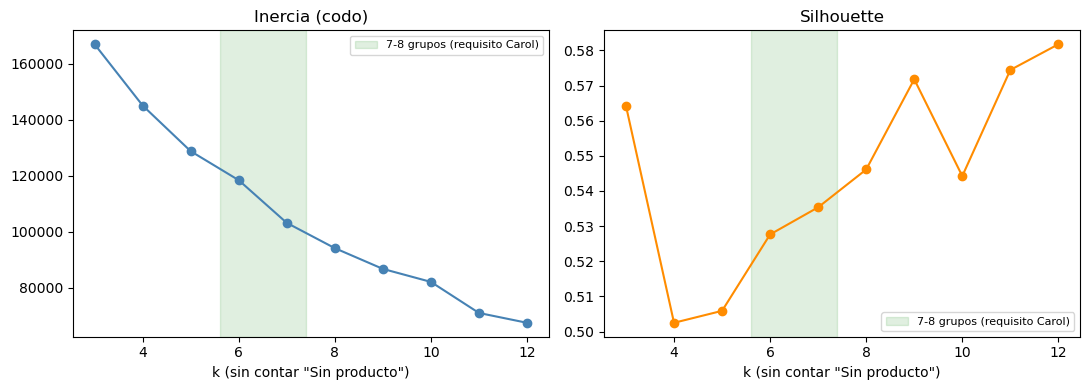


k elegido: 7 -> 8 grupos en total contando "Sin producto"


In [11]:
K_VALIDOS = [6, 7]   # 7 u 8 grupos en total contando "Sin producto" (requisito de Carol)

muestra = X_scaled.sample(n=min(30000, len(X_scaled)), random_state=42)

resultados = []
for k in range(3, 13):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    sil = silhouette_score(muestra, km.predict(muestra))
    resultados.append({'k': k, 'grupos_totales': k + 1, 'inercia': km.inertia_, 'silhouette': sil,
                       'valido_negocio': k in K_VALIDOS})
df_k = pd.DataFrame(resultados)
print(df_k.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for eje, col, color, titulo in [(ax[0], 'inercia', 'steelblue', 'Inercia (codo)'),
                                 (ax[1], 'silhouette', 'darkorange', 'Silhouette')]:
    eje.axvspan(min(K_VALIDOS) - 0.4, max(K_VALIDOS) + 0.4, color='green', alpha=0.12,
                label='7-8 grupos (requisito Carol)')
    eje.plot(df_k['k'], df_k[col], marker='o', color=color)
    eje.set_title(titulo); eje.set_xlabel('k (sin contar "Sin producto")'); eje.legend(fontsize=8)
plt.tight_layout(); plt.show()

K = int(df_k[df_k['k'].isin(K_VALIDOS)].sort_values('silhouette', ascending=False)['k'].iloc[0])
print(f'\nk elegido: {K} -> {K + 1} grupos en total contando "Sin producto"')

**Lectura de la elección.** Entre las dos opciones válidas, k=7 tiene mejor silhouette (0,535 frente a 0,528) y además reduce la inercia un 13 % respecto a k=6. Nos quedamos con **k=7, es decir, 8 grupos en total** contando "Sin producto".

In [12]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
df_con_producto['grupo'] = kmeans.fit_predict(X_scaled) + 1   # grupos 1..K (0 = Sin producto)

tamanos = df_con_producto['grupo'].value_counts().sort_index()
print(pd.DataFrame({'clientes': tamanos, 'pct': (tamanos / len(df_con_producto) * 100).round(1)}))

       clientes   pct
grupo                
1         17530   5.3
2        150929  45.8
3         51980  15.8
4         65178  19.8
5         16701   5.1
6          8464   2.6
7         18769   5.7


## 7. Perfil de cada grupo

In [13]:
perfil_num = df_con_producto.groupby('grupo').agg(
    clientes=('pk_cid', 'count'),
    edad_media=('age', 'mean'),
    renta_mediana=('salary', 'median'),
    antiguedad_media=('antiguedad_meses', 'mean'),
    n_productos_medio=('n_productos', 'mean'),
    n_compras_medio=('n_compras', 'mean'),
    margen_medio=('margen_total', 'mean'),
    pct_activos=('active_customer', 'mean'),
).round(2)
perfil_prod = (df_con_producto.groupby('grupo')[VARS_PROD].mean() * 100).round(1)
perfil_seg = (pd.crosstab(df_con_producto['grupo'], df_con_producto['segment'], normalize='index') * 100).round(1)

print(perfil_num, '\n')
print(perfil_prod, '\n')
print(perfil_seg)

       clientes  edad_media  renta_mediana  antiguedad_media  \
grupo                                                          
1         17530       49.06      100150.78             25.96   
2        150929       24.36       85308.06             31.66   
3         51980       42.64       87936.76             19.86   
4         65178       22.70       85308.06              9.16   
5         16701       40.79       86892.48             22.35   
6          8464       27.16       97616.70             27.92   
7         18769       41.40       87319.58             20.75   

       n_productos_medio  n_compras_medio  margen_medio  pct_activos  
grupo                                                                 
1                   1.81             1.13        564.80         0.84  
2                   1.03             0.02          0.98         0.27  
3                   1.05             0.61        123.57         0.71  
4                   1.09             1.08        125.57         0.47

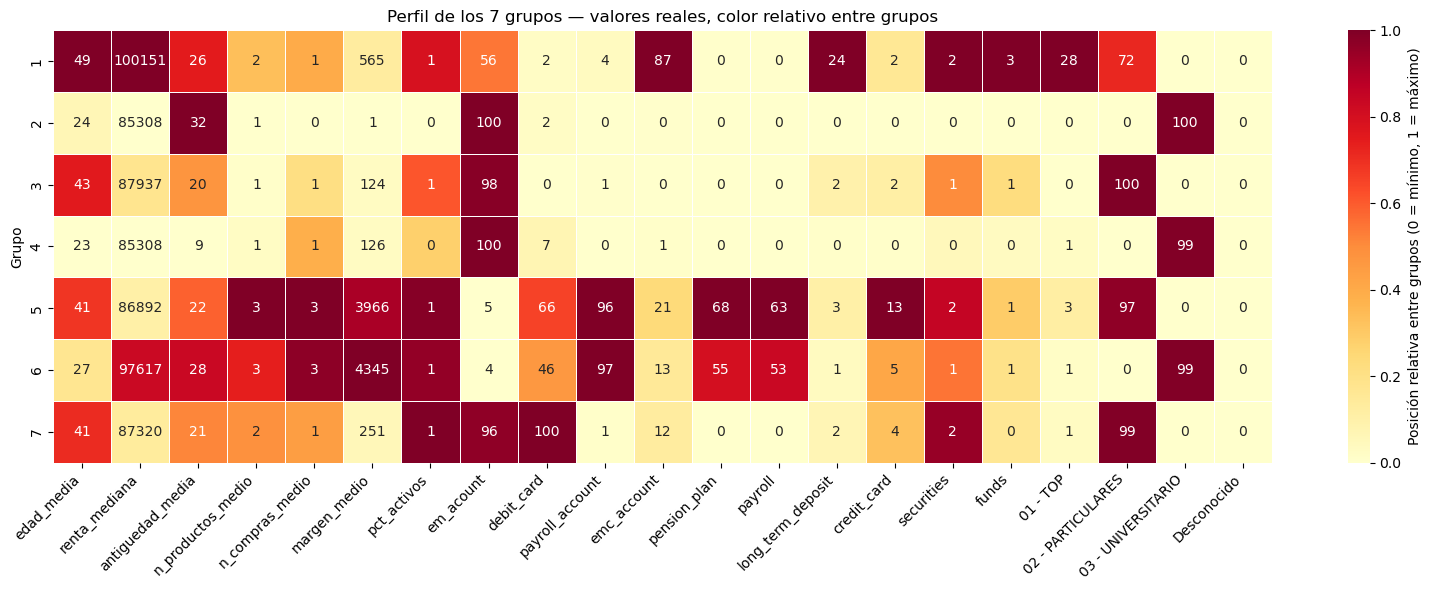

In [14]:
perfil = pd.concat([perfil_num.drop(columns=['clientes']), perfil_prod, perfil_seg], axis=1)
rango = (perfil.max() - perfil.min()).replace(0, 1)
perfil_norm = (perfil - perfil.min()) / rango

plt.figure(figsize=(16, 6))
sns.heatmap(perfil_norm, annot=perfil.round(0), fmt='g', cmap='YlOrRd', linewidths=0.5,
            cbar_kws={'label': 'Posición relativa entre grupos (0 = mínimo, 1 = máximo)'})
plt.title(f'Perfil de los {K} grupos — valores reales, color relativo entre grupos')
plt.ylabel('Grupo'); plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

### Validación: ¿pesa demasiado `salary`?

Es la variable con más imputación. Repetimos el K-Means sin ella y comparamos con el Adjusted Rand Index (1 = asignaciones idénticas, 0 = independientes). Un ARI alto indica que la segmentación no depende de los valores imputados.

In [15]:
grupo_sin_salary = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(X_scaled.drop(columns=['salary'])) + 1
ari = adjusted_rand_score(df_con_producto['grupo'], grupo_sin_salary)
print(f'Adjusted Rand Index con vs sin salary: {ari:.3f}')
print(pd.crosstab(df_con_producto['grupo'], grupo_sin_salary, rownames=['con salary'], colnames=['sin salary']))

Adjusted Rand Index con vs sin salary: 1.000
sin salary      1       2      3     4      5      6      7
con salary                                                 
1           17527       0      0     0      0      2      1
2               0  150929      0     0      0      0      0
3               1       0  51979     0      0      0      0
4               0       0      0     0      0  65178      0
5               1       0      0     0      0      0  16700
6               0       0      0  8462      0      2      0
7               0       0      0     0  18769      0      0


**Lectura.** ARI = 1,000: los grupos son idénticos con y sin `salary` (la tabla cruzada solo cambia la numeración). La segmentación no depende de los valores imputados. A la vez, esto indica que `salary` apenas pesa en la formación de los grupos: las diferencias de renta que aparecen en la tabla de perfiles describen a los grupos, pero no son lo que los define.

### Comprobación: ¿y si los clientes "Sin producto" entraran en el K-Means?

Hemos separado a mano a los clientes sin ningún producto (grupo 0). Para comprobar que esa decisión está respaldada por los datos, repetimos el K-Means **con todos los clientes** y con un grupo más (K+1, para mantener el mismo número total de grupos), y miramos dónde acaban los "Sin producto":

- Si quedan aislados en grupos formados casi solo por ellos, el algoritmo los separa por sí solo y separarlos a mano es equivalente.
- Si se mezclan con clientes con producto, habría que replantear la decisión.

Esta comprobación no cambia ningún resultado: es solo una validación.

In [16]:
todos = pd.concat([df_con_producto.drop(columns=['grupo']),
                   df_sin_producto],
                  ignore_index=True)
es_sin_producto = (todos['n_productos'] == 0)

X_todos = MinMaxScaler().fit_transform(preparar_matriz(todos))
grupo_todos = KMeans(n_clusters=K + 1, n_init=10, random_state=42).fit_predict(X_todos) + 1

tabla = pd.crosstab(grupo_todos, es_sin_producto.map({True: 'Sin producto', False: 'Con producto'}),
                    rownames=['grupo (K-Means con todos)'], colnames=[''])
print(tabla, '\n')

grupo_mayoritario = pd.Series(grupo_todos[es_sin_producto.values]).mode()[0]
en_su_grupo = (grupo_todos[es_sin_producto.values] == grupo_mayoritario).mean()
pureza = es_sin_producto[grupo_todos == grupo_mayoritario].mean()
print(f'Clientes "Sin producto" que caen en el mismo grupo (el {grupo_mayoritario}): {en_su_grupo:.1%}')
print(f'Proporción de "Sin producto" dentro de ese grupo: {pureza:.1%}')

                           Con producto  Sin producto
grupo (K-Means con todos)                            
1                                150823             0
2                                 51741             0
3                                  3405         60825
4                                  4273         49167
5                                 65585             0
6                                 19171             0
7                                 19113             0
8                                 15440             0 

Clientes "Sin producto" que caen en el mismo grupo (el 3): 55.3%
Proporción de "Sin producto" dentro de ese grupo: 94.7%


**Lectura.** Los 109.992 clientes "Sin producto" acaban todos en dos grupos (3 y 4), y los dos están formados casi solo por ellos (94,7 % y 92,0 %). El 55,3 % que imprime la celda solo cuenta el grupo mayoritario.

El reparto entre ambos grupos (60.825 y 49.167) prácticamente coincide con los universitarios (60.822) y particulares (48.174) sin producto de la sección 2: el K-Means los aísla y además los divide por segmento. Es decir, no los mezcla con los clientes con producto, pero gasta dos de los ocho grupos en ellos.

Separarlos a mano da el mismo resultado de negocio y deja los siete grupos del K-Means para diferenciar a los clientes con producto, que son los relevantes para el cross-selling.

## 8. Nombres de negocio

El K-Means solo numera los grupos, y esa numeración es arbitraria: puede cambiar si el modelo se reentrena con otros datos o parámetros. Para que los nombres no dependan de ella, se asignan **a partir del perfil de la sección 7**, con reglas que cualquiera puede comprobar en la tabla:

| Orden | Regla | Nombre |
|---|---|---|
| 1 | `payroll_account` ≥ 80 % y mayoría universitaria | Universitarios con nómina |
| 1 | `payroll_account` ≥ 80 % y mayoría particulares | Particulares con nómina |
| 2 | `debit_card` ≥ 80 % | Particulares con tarjeta |
| 3 | De los que quedan, la renta mediana más alta | TOP ahorradores |
| 4 | De los universitarios que quedan, la menor antigüedad | Universitarios recién llegados |
| 5 | El resto de universitarios | Universitarios inactivos |
| 6 | El resto | Particulares básicos |

Si dos grupos acaban con el mismo nombre, el notebook **se detiene**: significa que la estructura de los grupos ha cambiado y hay que revisar las reglas con la tabla de perfiles.

In [17]:
def nombrar_grupos(perfil_num, perfil_prod, perfil_seg):
    univ = perfil_seg['03 - UNIVERSITARIO'] if '03 - UNIVERSITARIO' in perfil_seg else pd.Series(0, index=perfil_num.index)
    pendientes = list(perfil_num.index)
    nombres = {}

    def asignar(g, nombre):
        nombres[g] = nombre
        pendientes.remove(g)

    for g in [g for g in pendientes if perfil_prod.loc[g, 'payroll_account'] >= 80]:
        asignar(g, 'Universitarios con nómina' if univ[g] >= 50 else 'Particulares con nómina')
    for g in [g for g in pendientes if perfil_prod.loc[g, 'debit_card'] >= 80]:
        asignar(g, 'Particulares con tarjeta')
    if pendientes:
        asignar(perfil_num.loc[pendientes, 'renta_mediana'].idxmax(), 'TOP ahorradores')
    universitarios = [g for g in pendientes if univ[g] >= 50]
    if universitarios:
        asignar(perfil_num.loc[universitarios, 'antiguedad_media'].idxmin(), 'Universitarios recién llegados')
    for g in [g for g in pendientes if univ[g] >= 50]:
        asignar(g, 'Universitarios inactivos')
    for g in list(pendientes):
        asignar(g, 'Particulares básicos')
    return nombres

nombres_grupo = {0: 'Sin producto', **nombrar_grupos(perfil_num, perfil_prod, perfil_seg)}

repetidos = pd.Series(nombres_grupo).value_counts()
assert (repetidos == 1).all(), f'Nombres repetidos {list(repetidos[repetidos > 1].index)}: revisa las reglas con la tabla de perfiles'
assert set(nombres_grupo) == set(range(K + 1))

resumen_nombres = perfil_num[['clientes', 'edad_media', 'renta_mediana', 'antiguedad_media', 'pct_activos']].copy()
resumen_nombres['payroll_account_%'] = perfil_prod['payroll_account']
resumen_nombres['pension_plan_%'] = perfil_prod['pension_plan']
resumen_nombres['debit_card_%'] = perfil_prod['debit_card']
resumen_nombres.insert(0, 'nombre', pd.Series(nombres_grupo))
print(resumen_nombres.to_string())

                               nombre  clientes  edad_media  renta_mediana  antiguedad_media  pct_activos  payroll_account_%  pension_plan_%  debit_card_%
grupo                                                                                                                                                     
1                     TOP ahorradores     17530       49.06      100150.78             25.96         0.84                3.6             0.4           2.2
2            Universitarios inactivos    150929       24.36       85308.06             31.66         0.27                0.0             0.0           2.2
3                Particulares básicos     51980       42.64       87936.76             19.86         0.71                0.7             0.0           0.0
4      Universitarios recién llegados     65178       22.70       85308.06              9.16         0.47                0.0             0.1           7.4
5             Particulares con nómina     16701       40.79       8689

## 9. Exportar los grupos de abril (para evaluar en la Tarea 4)

In [18]:
df_sin_producto['grupo'] = 0
grupos_abril = pd.concat([df_sin_producto[['pk_cid', 'grupo']],
                          df_con_producto[['pk_cid', 'grupo']]], ignore_index=True)
grupos_abril['nombre_grupo'] = grupos_abril['grupo'].map(nombres_grupo)

assert grupos_abril['pk_cid'].is_unique
print('Clientes:', len(grupos_abril))
print(grupos_abril['nombre_grupo'].value_counts())
grupos_abril.to_csv(RUTA + 'clientes_grupos_abril.csv', index=False)
print('Guardado en', RUTA + 'clientes_grupos_abril.csv')

Clientes: 439543
nombre_grupo
Universitarios inactivos          150929
Sin producto                      109992
Universitarios recién llegados     65178
Particulares básicos               51980
Particulares con tarjeta           18769
TOP ahorradores                    17530
Particulares con nómina            16701
Universitarios con nómina           8464
Name: count, dtype: int64
Guardado en ../data/processed/clientes_grupos_abril.csv


## 10. Asignar grupos con la foto de mayo (para la campaña)

Para la campaña de junio queremos el estado más reciente de cada cliente. **No se reentrena:** se construye la tabla de mayo con la misma función, se aplica el mismo `scaler` y se usa `kmeans.predict()`. Los centroides son los mismos, así que el grupo 3 de mayo significa lo mismo que el grupo 3 de abril.

In [19]:
clientes_mayo = construir_tabla_clientes(df, MES_ULTIMO)
sin_mayo = clientes_mayo[clientes_mayo['n_productos'] == 0][['pk_cid']].assign(grupo=0)
con_mayo = clientes_mayo[clientes_mayo['n_productos'] >= 1].copy().reset_index(drop=True)

X_mayo = pd.DataFrame(scaler.transform(preparar_matriz(con_mayo)[X.columns]), columns=X.columns)
con_mayo['grupo'] = kmeans.predict(X_mayo) + 1

grupos_mayo = pd.concat([sin_mayo, con_mayo[['pk_cid', 'grupo']]], ignore_index=True)
grupos_mayo['nombre_grupo'] = grupos_mayo['grupo'].map(nombres_grupo)
assert grupos_mayo['pk_cid'].is_unique

print('Clientes:', len(grupos_mayo))
print(grupos_mayo['nombre_grupo'].value_counts())
grupos_mayo.to_csv(RUTA + 'clientes_grupos.csv', index=False)
print('Guardado en', RUTA + 'clientes_grupos.csv')

Clientes: 442909
nombre_grupo
Universitarios inactivos          150390
Sin producto                      111382
Universitarios recién llegados     66271
Particulares básicos               50930
Particulares con tarjeta           19303
TOP ahorradores                    18313
Particulares con nómina            17457
Universitarios con nómina           8863
Name: count, dtype: int64
Guardado en ../data/processed/clientes_grupos.csv


### Estabilidad abril → mayo

¿Cuántos clientes cambian de grupo en un mes? Si casi todos se quedan en el mismo, los grupos son estables y tiene sentido planificar campañas sobre ellos. Los que cambian (por ejemplo, de "Particulares con tarjeta" a "Particulares con nómina") son justo las conversiones que buscamos.

In [20]:
transicion = grupos_abril.merge(grupos_mayo, on='pk_cid', suffixes=('_abril', '_mayo'))
mismo = (transicion['grupo_abril'] == transicion['grupo_mayo']).mean()
print(f'Clientes presentes en ambos meses: {len(transicion)} | mismo grupo: {mismo:.1%}')
print(pd.crosstab(transicion['nombre_grupo_abril'], transicion['nombre_grupo_mayo']))

Clientes presentes en ambos meses: 438321 | mismo grupo: 97.3%
nombre_grupo_mayo               Particulares básicos  Particulares con nómina  \
nombre_grupo_abril                                                              
Particulares básicos                           47965                      435   
Particulares con nómina                           64                    16271   
Particulares con tarjeta                        1511                      394   
Sin producto                                    1100                      118   
TOP ahorradores                                   61                      173   
Universitarios con nómina                          0                       48   
Universitarios inactivos                         121                        1   
Universitarios recién llegados                    39                        4   

nombre_grupo_mayo               Particulares con tarjeta  Sin producto  \
nombre_grupo_abril                                  

**Lectura.** El 97,3 % de los clientes presentes en ambos meses sigue en el mismo grupo, así que la segmentación es estable de un mes a otro. Los cambios más numerosos se dan entre "Particulares básicos" y "Particulares con tarjeta", en los dos sentidos (alta o baja de la tarjeta de débito), y entre clientes "Sin producto" que contratan su primer producto (1.100 pasan a "Particulares básicos"). Los pasos hacia "Particulares con nómina" (435 desde básicos, 394 desde tarjeta) son el tipo de conversión que persigue la campaña.

## Resultado

- `clientes_grupos_abril.csv`: grupos con la foto de abril. Úsalo en la Tarea 4 para medir conversiones de mayo por grupo sin leakage.
- `clientes_grupos.csv`: grupos con la foto de mayo, asignados con el modelo de abril. Úsalo para definir la campaña de junio.

Ambos cubren el mismo universo que la Tarea 2: base común, sin fallecidos.